# Polynomial Regression: Temperature and Pressure

This exercise investigates the relationship between temperature and pressure.

The relationship is curved rather than a straight line, so we will use
polynomial regression to build a model that follows the data more accurately.

In [1]:
# Import pandas for loading and working with the CSV dataset.
import pandas as pd

# Import NumPy for numerical calculations and creating smooth graph values.
import numpy as np

# Import Matplotlib for plotting the temperature and pressure data.
import matplotlib.pyplot as plt

# Import the tools required to create polynomial features
# and train a linear regression model.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Loading and Inspecting the Dataset

The dataset contains temperature measurements and their corresponding pressure
values. We first load the CSV file and inspect its structure before building
the polynomial regression model.

In [2]:
# Load the CSV file.
#
# The file is in the same Week5 folder as this notebook,
# so we only need to provide its filename.
data = pd.read_csv("week5_data.csv")

# Display the complete dataset.
data

,sno,Temperature,Pressure
0,1,0,0.0002
1,2,20,0.0012
2,3,40,0.0060
3,4,60,0.0300
4,5,80,0.0900
5,6,100,0.2700


In [3]:
# Display information about the dataset.
#
# This shows the column names, data types and whether
# any values are missing.
data.info()

# Count missing values in each column.
print("\nMissing values:")
print(data.isnull().sum())

# Display useful statistical information.
print("\nSummary statistics:")
display(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sno          6 non-null      int64  
 1   Temperature  6 non-null      int64  
 2   Pressure     6 non-null      float64
dtypes: float64(1), int64(2)
memory usage: 276.0 bytes

Missing values:
sno            0
Temperature    0
Pressure       0
dtype: int64

Summary statistics:


,sno,Temperature,Pressure
count,6.000000,6.000000,6.000000
mean,3.500000,50.000000,0.066233
std,1.870829,37.416574,0.105467
min,1.000000,0.000000,0.000200
25%,2.250000,25.000000,0.002400
50%,3.500000,50.000000,0.018000
75%,4.750000,75.000000,0.075000
max,6.000000,100.000000,0.270000


## 2. Selecting the Input and Target Variables

`Temperature` is the independent variable (X) supplied to the model.

`Pressure` is the dependent variable (y) that the model will learn to predict.

The `sno` column is only a row identifier, so it is not used for training.

In [4]:
# Select Temperature as the input feature.
#
# The double square brackets keep X as a two-dimensional table.
# Scikit-learn expects the input features in this format.
X = data[["Temperature"]]

# Select Pressure as the target value that we want to predict.
y = data["Pressure"]

# Display both variables so we can check them.
print("Input feature (X):")
display(X)

print("Target variable (y):")
display(y)

Input feature (X):


,Temperature
0,0
1,20
2,40
3,60
4,80
5,100


Target variable (y):


0    0.0002
1    0.0012
2    0.0060
3    0.0300
4    0.0900
5    0.2700
Name: Pressure, dtype: float64

## 3. Visualising the Original Data

A scatter plot helps us examine the relationship before selecting a model.

If the points form a curve rather than a straight line, ordinary linear
regression may not describe the relationship accurately. Polynomial regression
can represent this curved pattern.

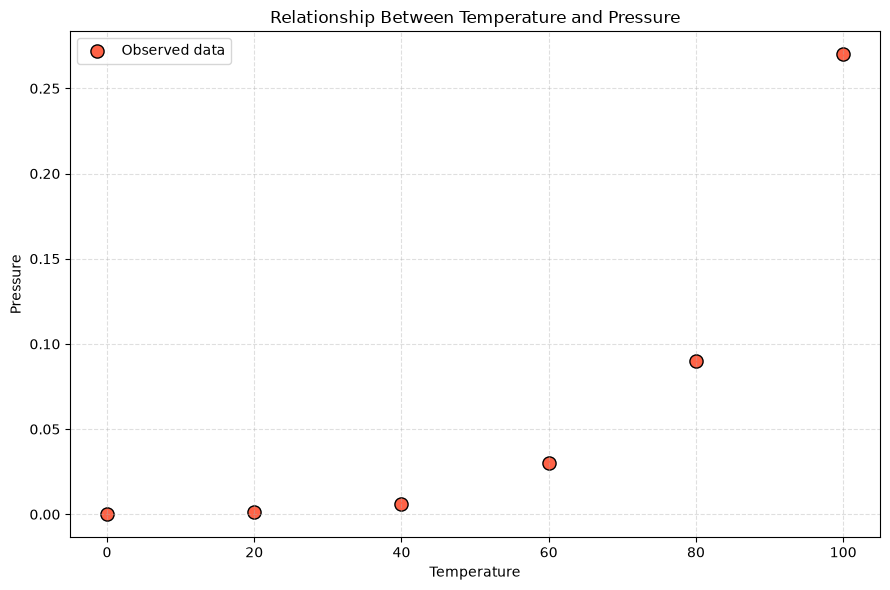

In [5]:
# Create a figure for the scatter plot.
plt.figure(figsize=(9, 6))

# Plot each temperature and its corresponding pressure.
plt.scatter(
    X["Temperature"],
    y,
    color="tomato",
    s=90,
    edgecolor="black",
    label="Observed data"
)

# Add a title and axis labels.
plt.title("Relationship Between Temperature and Pressure")
plt.xlabel("Temperature")
plt.ylabel("Pressure")

# Add a light grid and legend to improve readability.
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

# Prevent labels from being cut off and display the graph.
plt.tight_layout()
plt.show()

## 4. Creating Polynomial Features

The scatter plot shows that pressure does not increase in a straight line.

Polynomial regression handles this curve by creating additional versions of
the temperature feature. For a degree-three model, it creates:

- Temperature
- Temperature²
- Temperature³

The model can combine these features to create a curved prediction line.

In [6]:
# Create a polynomial feature transformer.
#
# degree=3 means that Temperature, Temperature² and Temperature³
# will be supplied to the regression model.
#
# include_bias=False prevents an unnecessary column containing only ones.
polynomial_converter = PolynomialFeatures(
    degree=3,
    include_bias=False
)

# Transform the original Temperature column into polynomial features.
X_polynomial = polynomial_converter.fit_transform(X)

# Display the names of the newly created features.
feature_names = polynomial_converter.get_feature_names_out(
    ["Temperature"]
)

# Place the transformed values in a DataFrame
# so they are easier to understand.
polynomial_data = pd.DataFrame(
    X_polynomial,
    columns=feature_names
)

print("Polynomial features:")
display(polynomial_data)

Polynomial features:


,Temperature,Temperature^2,Temperature^3
0,0.0,0.0,0.0
1,20.0,400.0,8000.0
2,40.0,1600.0,64000.0
3,60.0,3600.0,216000.0
4,80.0,6400.0,512000.0
5,100.0,10000.0,1000000.0


## 5. Training the Polynomial Regression Model

`PolynomialFeatures` creates the additional curved features, but it does not
make predictions itself.

We now train a linear regression model using Temperature, Temperature² and
Temperature³. Although `LinearRegression` is used, the final relationship is
curved because the model receives polynomial features.

In [7]:
# Create the regression model.
polynomial_model = LinearRegression()

# Train the model using the polynomial temperature features
# and the known pressure values.
polynomial_model.fit(X_polynomial, y)

# Confirm that the training stage has finished.
print("Polynomial regression model trained successfully.")

Polynomial regression model trained successfully.


In [8]:
# Use the trained model to predict pressure for
# every temperature in the original dataset.
predicted_pressure = polynomial_model.predict(X_polynomial)

# Create a comparison table containing the real and predicted values.
results = pd.DataFrame({
    "Temperature": X["Temperature"],
    "Actual_Pressure": y,
    "Predicted_Pressure": predicted_pressure
})

# Calculate the residual for every observation.
#
# A residual is the difference between the real value
# and the model's predicted value.
results["Residual"] = (
    results["Actual_Pressure"]
    - results["Predicted_Pressure"]
)

# Display values using six decimal places.
display(results.round(6))

,Temperature,Actual_Pressure,Predicted_Pressure,Residual
0,0,0.0002,-0.001989,0.002189
1,20,0.0012,0.007244,-0.006044
2,40,0.0060,0.003711,0.002289
3,60,0.0300,0.022489,0.007511
4,80,0.0900,0.098656,-0.008656
5,100,0.2700,0.267289,0.002711


## 6. Visualising the Polynomial Regression Curve

The original observations are displayed as individual points.

The polynomial regression curve shows the pressure values predicted by the
trained model across the full temperature range.

c:\Users\zeale\anaconda3\envs\University\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


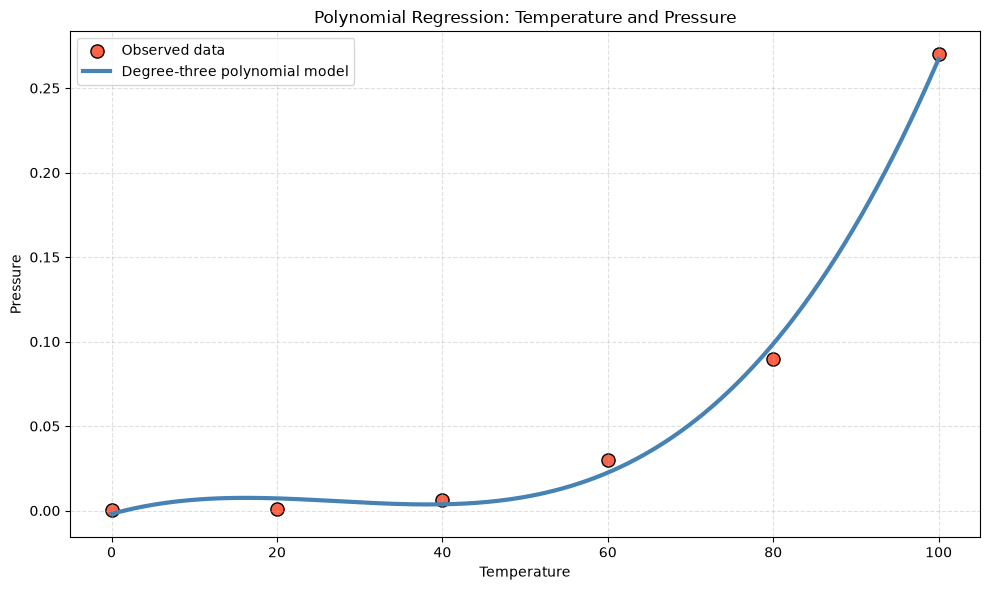

In [9]:
# Create many evenly spaced temperature values.
#
# Using many values instead of only the six original temperatures
# produces a smooth prediction curve.
temperature_range = np.linspace(
    X["Temperature"].min(),
    X["Temperature"].max(),
    300
).reshape(-1, 1)

# Convert the new temperature values into the same polynomial
# features used during model training.
temperature_range_polynomial = polynomial_converter.transform(
    temperature_range
)

# Predict pressure across the complete temperature range.
pressure_curve = polynomial_model.predict(
    temperature_range_polynomial
)

# Create the graph.
plt.figure(figsize=(10, 6))

# Plot the original observations.
plt.scatter(
    X["Temperature"],
    y,
    color="tomato",
    edgecolor="black",
    s=90,
    label="Observed data"
)

# Plot the smooth polynomial regression curve.
plt.plot(
    temperature_range,
    pressure_curve,
    color="steelblue",
    linewidth=3,
    label="Degree-three polynomial model"
)

# Add labels and formatting.
plt.title("Polynomial Regression: Temperature and Pressure")
plt.xlabel("Temperature")
plt.ylabel("Pressure")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()